
# Plant Disease Classification

## Part 1: Data Exploration

### Objective
Explore the plant disease image dataset by visualizing sample images
from five disease classes, analyzing the class distribution, and
identifying key insights that may influence model development.


In [66]:
from pathlib import Path
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import json
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf

In [40]:
DATASET_PATH = Path(r"PlantVillage")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")

class_folders = sorted([
    folder for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
])

print("Dataset path:", DATASET_PATH)
print("Number of classes:", len(class_folders))


Dataset path: PlantVillage
Number of classes: 15



### 1. Sample Images from Five Disease Classes

Visualize three sample images from each of five disease classes
to observe differences in leaf appearance and disease symptoms.


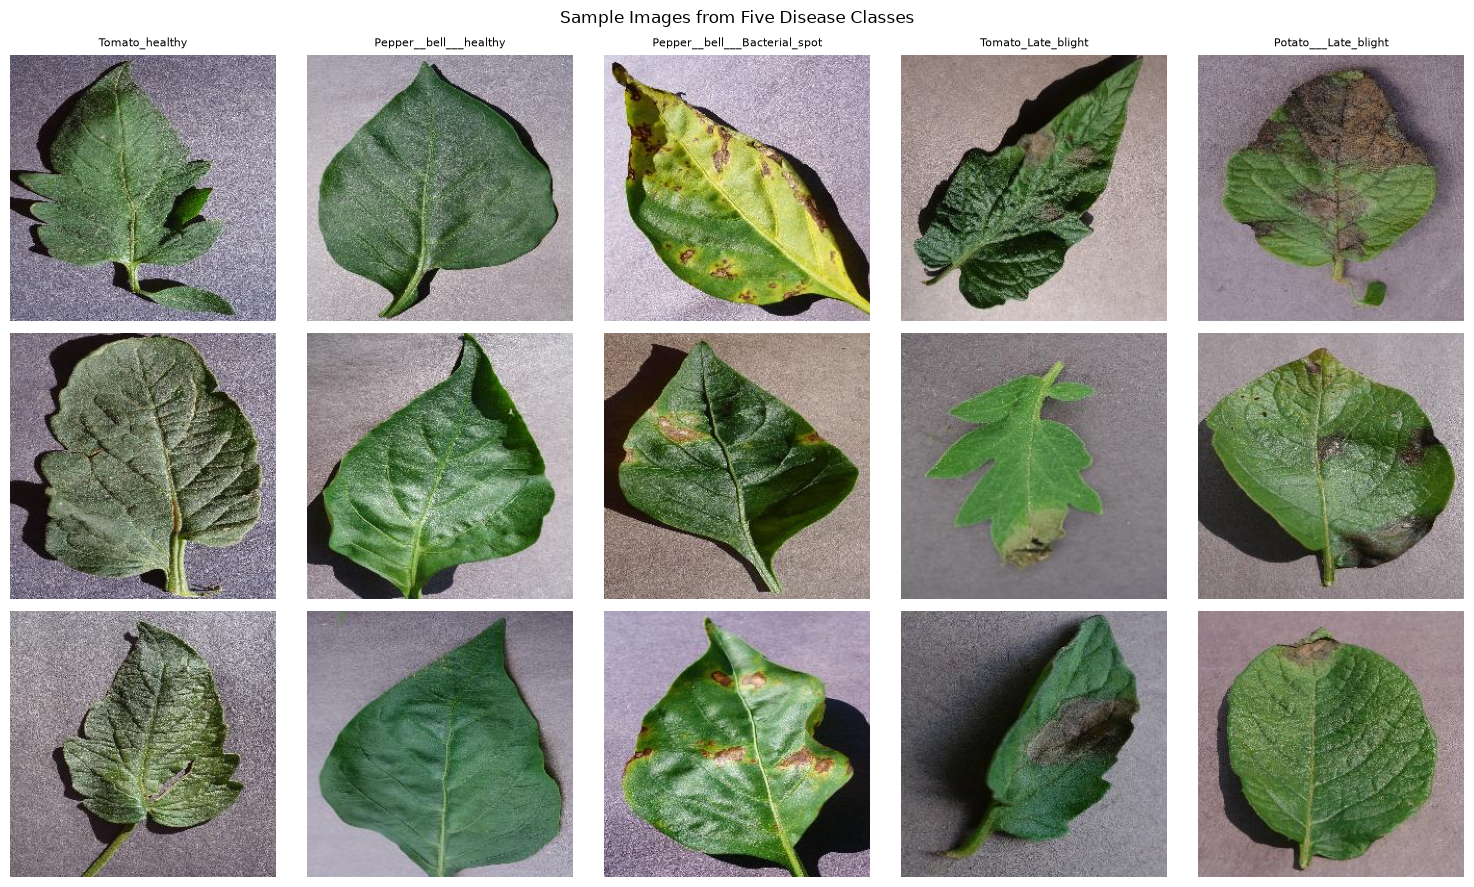

In [41]:

random.seed(42)

selected_classes = random.sample(class_folders, 5)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for col, folder in enumerate(selected_classes):
    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(images, min(3, len(images)))

    axes[0, col].set_title(folder.name, fontsize=8)

    for row in range(3):
        axes[row, col].axis("off")

        if row < len(samples):
            with Image.open(samples[row]) as img:
                axes[row, col].imshow(img.convert("RGB"))

plt.suptitle("Sample Images from Five Disease Classes")
plt.tight_layout()
plt.show()



### 2. Class Distribution

Count the images in each disease class and visualize the
distribution using a bar chart.


Total images: 20,638
Total classes: 15


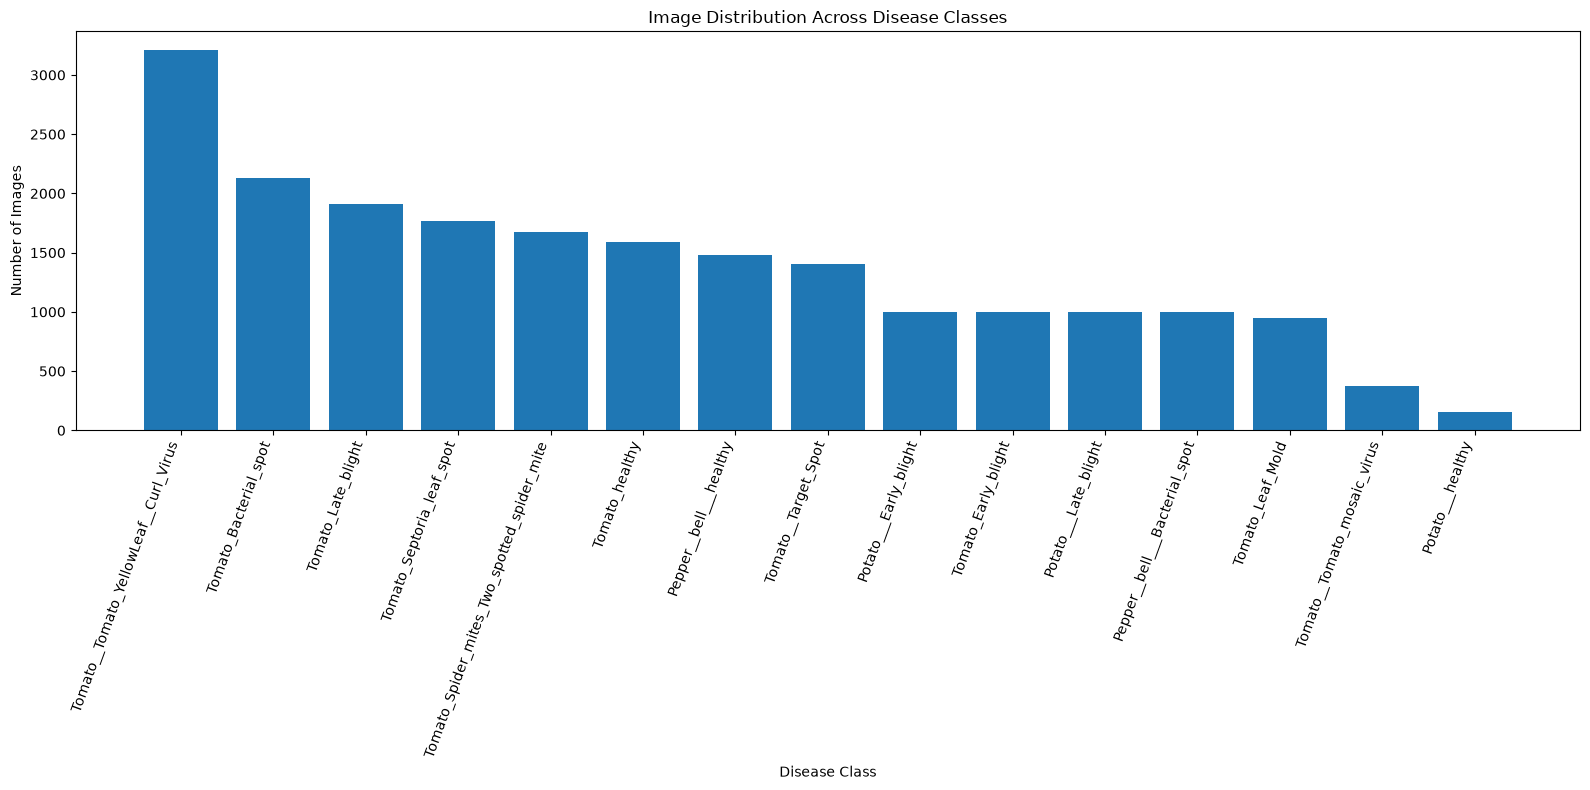

In [43]:

class_counts = []

for folder in class_folders:
    count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    class_counts.append({
        "Class": folder.name,
        "Image_Count": count
    })

class_df = pd.DataFrame(class_counts).sort_values(
    "Image_Count", ascending=False
).reset_index(drop=True)

total_images = class_df["Image_Count"].sum()

print("Total images:", f"{total_images:,}")
print("Total classes:", len(class_df))

plt.figure(figsize=(16, 8))
plt.bar(class_df["Class"], class_df["Image_Count"])
plt.title("Image Distribution Across Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()



### 3. Key Insights

1. The dataset contains 20,638 images across 15 plant disease
   and healthy-leaf classes.

2. The class distribution is imbalanced. Tomato Yellow Leaf Curl
   Virus has 3,208 images, while Potato Healthy has only 152 images.

3. Differences in disease symptoms and similarities between certain
   classes may make some diseases more difficult to classify correctly.



# Part 2: Model Building

## 1. Dataset Splitting

Split the original dataset into training, validation, and test sets
using stratified sampling within each class.

- Training: 70%
- Validation: 15%
- Test: 15%

The validation set will be used for model selection, while the
test set will be reserved for final performance evaluation.


In [ ]:
records = []

for folder in class_folders:
    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in images:
        records.append({
            "filepath": str(image_path),
            "label": folder.name
        })

df = pd.DataFrame(records)

train_parts, val_parts, test_parts = [], [], []

for class_name, group in df.groupby("label"):
    train_val, test = train_test_split(
        group,
        test_size=0.15,
        random_state=42
    )

    train, val = train_test_split(
        train_val,
        test_size=0.15 / 0.85,
        random_state=42
    )

    train_parts.append(train)
    val_parts.append(val)
    test_parts.append(test)

train_df = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
val_df = pd.concat(val_parts).sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))


Train: 14437
Validation: 3100
Test: 3101
Total: 20638


In [44]:

# 1. Check class distribution in every split
split_summary = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).fillna(0).astype(int)

display(split_summary)

# 2. Check that no file path appears in multiple splits
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("Train-Val overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Val-Test overlap:", len(val_paths & test_paths))

# 3. Check all images are accounted for exactly once
all_split_paths = train_paths | val_paths | test_paths

print("Unique images in all splits:", len(all_split_paths))
print("Original dataset images:", len(df))

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)
assert len(all_split_paths) == len(df)

# 4. Check every class exists in all three splits
assert (split_summary > 0).all().all()

print("\nPASS: No file-path overlap.")
print("PASS: Every class exists in all three splits.")
print("PASS: All dataset images are accounted for.")


,Train,Validation,Test
label,,,
Pepper__bell___Bacterial_spot,697,150,150
Pepper__bell___healthy,1034,222,222
Potato___Early_blight,700,150,150
Potato___Late_blight,700,150,150
Potato___healthy,106,23,23
Tomato_Bacterial_spot,1488,319,320
Tomato_Early_blight,700,150,150
Tomato_Late_blight,1335,287,287
Tomato_Leaf_Mold,666,143,143


Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
Unique images in all splits: 20638
Original dataset images: 20638

PASS: No file-path overlap.
PASS: Every class exists in all three splits.
PASS: All dataset images are accounted for.



### 2. Prepare TensorFlow Datasets

Convert the train, validation, and test image paths into TensorFlow
datasets. Resize images to 224 × 224 pixels and process them in
batches to avoid loading the entire dataset into memory.

Image augmentation will be applied only to training images.


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = [folder.name for folder in class_folders]

CLASS_TO_INDEX = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

print("Number of classes:", len(CLASS_NAMES))
print(CLASS_TO_INDEX)

def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()
    labels = dataframe["label"].map(CLASS_TO_INDEX).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)
        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    return dataset.prefetch(AUTOTUNE)

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Number of classes: 15
{'Pepper__bell___Bacterial_spot': 0, 'Pepper__bell___healthy': 1, 'Potato___Early_blight': 2, 'Potato___healthy': 3, 'Potato___Late_blight': 4, 'Tomato__Target_Spot': 5, 'Tomato__Tomato_mosaic_virus': 6, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 7, 'Tomato_Bacterial_spot': 8, 'Tomato_Early_blight': 9, 'Tomato_healthy': 10, 'Tomato_Late_blight': 11, 'Tomato_Leaf_Mold': 12, 'Tomato_Septoria_leaf_spot': 13, 'Tomato_Spider_mites_Two_spotted_spider_mite': 14}
Train batches: 452
Validation batches: 97
Test batches: 97



### 3. Image Augmentation

Apply random horizontal flipping, rotation, and zoom to training
images to improve the model's ability to generalize to variations
in leaf orientation and image framing.

Augmentation is applied during training only. Validation and test
images remain unchanged for fair performance evaluation.


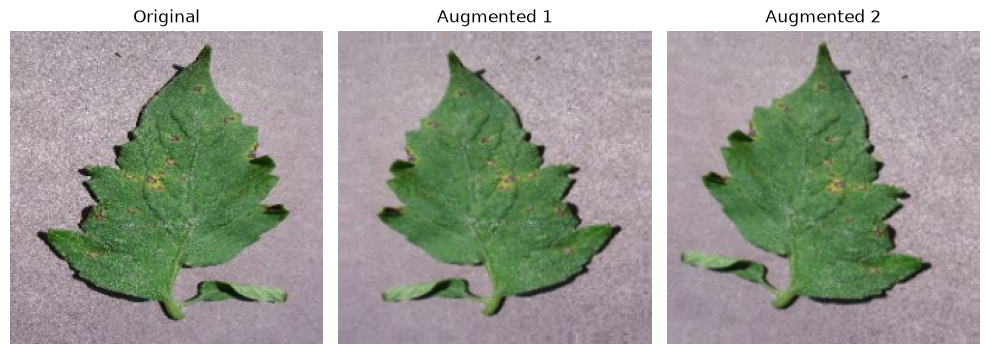

In [47]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

# Visualize the original image and two augmented versions
for images, labels in train_ds.take(1):
    sample_image = images[0:1]

    augmented_1 = data_augmentation(sample_image, training=True)
    augmented_2 = data_augmentation(sample_image, training=True)

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))

    axes[0].imshow(tf.cast(sample_image[0], tf.uint8).numpy())
    axes[0].set_title("Original")

    axes[1].imshow(
        tf.cast(tf.clip_by_value(augmented_1[0], 0, 255), tf.uint8).numpy()
    )
    axes[1].set_title("Augmented 1")

    axes[2].imshow(
        tf.cast(tf.clip_by_value(augmented_2[0], 0, 255), tf.uint8).numpy()
    )
    axes[2].set_title("Augmented 2")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


### 4. Model Architecture — MobileNetV2

MobileNetV2 is a lightweight convolutional neural network
pretrained on ImageNet. We use it as a feature extractor and
replace its original classification head with a new output layer
for our 15 plant disease classes.

The pretrained base is frozen initially to reduce training time.


In [48]:

NUM_CLASSES = len(CLASS_NAMES)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


### 5. Model Training

Train the MobileNetV2 classification head using the training dataset.
Monitor validation loss and accuracy to track generalization and
save the best model checkpoint.


In [ ]:
MODEL_DIR = Path("model_artifacts")
MODEL_DIR.mkdir(exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.5690 - loss: 1.4063
Epoch 1: val_loss improved from None to 0.50364, saving model to model_artifacts\best_mobilenetv2.keras

Epoch 1: finished saving model to model_artifacts\best_mobilenetv2.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 256s 554ms/step - accuracy: 0.7033 - loss: 0.9490 - val_accuracy: 0.8474 - val_loss: 0.5036 - learning_rate: 0.0010
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.8255 - loss: 0.5460
Epoch 2: val_loss improved from 0.50364 to 0.42577, saving model to model_artifacts\best_mobilenetv2.keras

Epoch 2: finished saving model to model_artifacts\best_mobilenetv2.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 229s 506ms/step - accuracy: 0.8336 - loss: 0.5146 - val_accuracy: 0.8671 - val_loss: 0.4258 - learning_rate: 0.0010
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.8510 - loss: 0.4579
Epoch 3: val_loss improved from 0.42577 to 0.41205, saving model to model_artifacts\bes


### 6. Training and Validation Performance

Visualize training and validation accuracy and loss across epochs
to understand model convergence and identify potential overfitting.


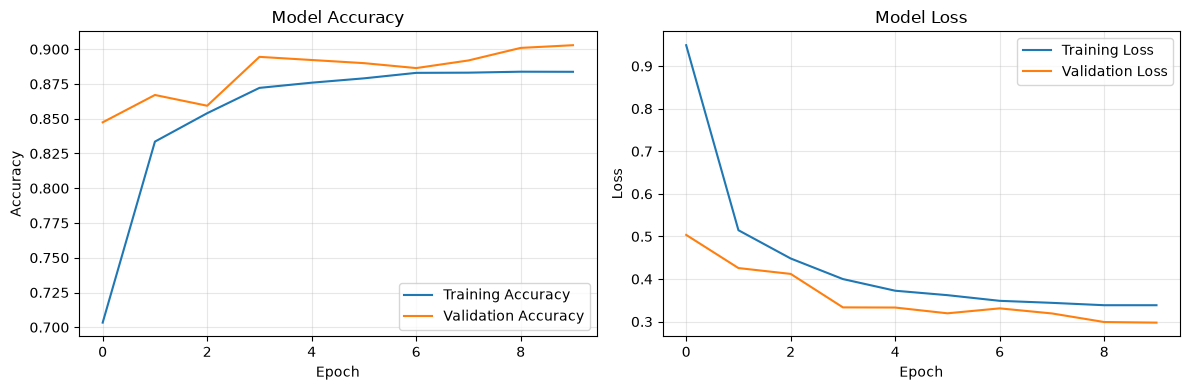

In [50]:

history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history_df["accuracy"], label="Training Accuracy")
axes[0].plot(history_df["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history_df["loss"], label="Training Loss")
axes[1].plot(history_df["val_loss"], label="Validation Loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 7. Validation Performance Evaluation

Evaluate the trained model on the validation dataset using
accuracy, precision, recall, F1-score, and a confusion matrix.

This helps identify classes where the model performs well
and classes that require further improvement.


97/97 ━━━━━━━━━━━━━━━━━━━━ 45s 454ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9202    1.0000    0.9585       150
                     Pepper__bell___healthy     1.0000    0.9505    0.9746       222
                      Potato___Early_blight     0.9797    0.9667    0.9732       150
                           Potato___healthy     0.7586    0.9565    0.8462        23
                       Potato___Late_blight     0.9267    0.9267    0.9267       150
                        Tomato__Target_Spot     0.7820    0.7820    0.7820       211
                Tomato__Tomato_mosaic_virus     0.9767    0.7500    0.8485        56
      Tomato__Tomato_YellowLeaf__Curl_Virus     0.9873    0.9668    0.9769       482
                      Tomato_Bacterial_spot     0.8596    0.9404    0.8982       319
                        Tomato_Early_blight     0.9605    0.4867    0.6460       150
                      

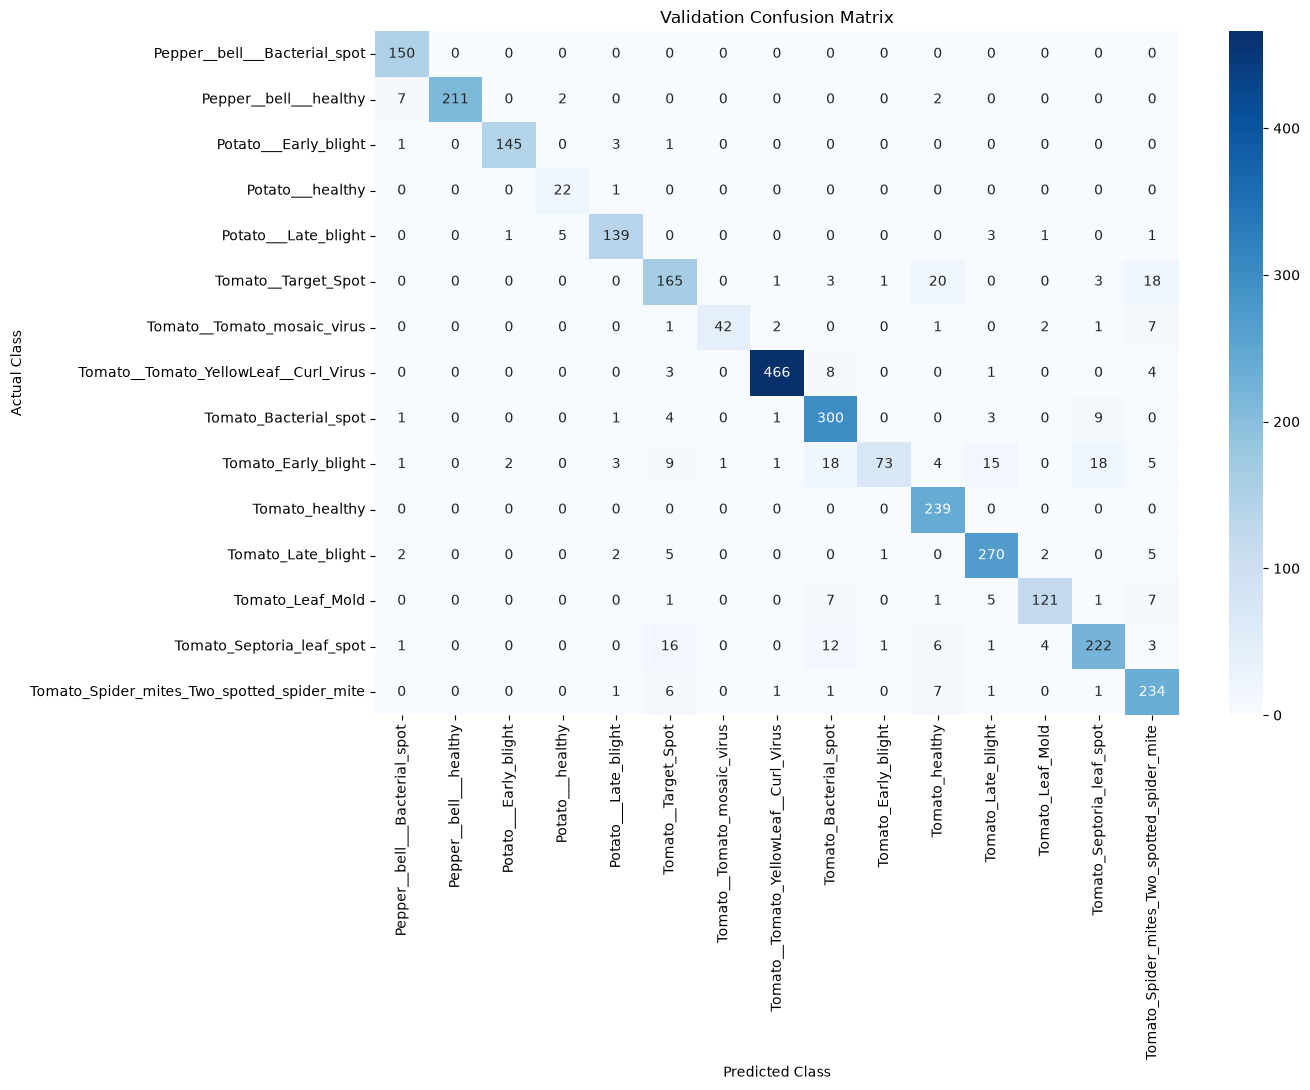

In [ ]:
# Load best checkpoint
best_model = tf.keras.models.load_model(
    "model_artifacts/best_mobilenetv2.keras"
)

# True labels
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

# Predictions
y_prob = best_model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



# Part 3: Evaluation and Business Impact

## 1. Test Set Evaluation

Evaluate the trained model on the previously separated test dataset.
Measure classification accuracy, precision, recall, and F1-score.

The test dataset has not been used during model training or
validation-based model selection.


In [ ]:
# Load the best saved model
best_model = tf.keras.models.load_model(
    "model_artifacts/best_mobilenetv2.keras"
)

# Evaluate on test dataset
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

97/97 ━━━━━━━━━━━━━━━━━━━━ 43s 415ms/step - accuracy: 0.8978 - loss: 0.3196
Test Accuracy: 0.8978
Test Loss: 0.3196



## 2. Classification Report and Confusion Matrix

Analyze the model's performance across all 15 classes using
a classification report and confusion matrix.

This helps identify disease categories where the model performs
well and categories where misclassification occurs.


97/97 ━━━━━━━━━━━━━━━━━━━━ 44s 438ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9255    0.9933    0.9582       150
                     Pepper__bell___healthy     0.9861    0.9595    0.9726       222
                      Potato___Early_blight     0.9671    0.9800    0.9735       150
                           Potato___healthy     0.8519    1.0000    0.9200        23
                       Potato___Late_blight     0.9333    0.9333    0.9333       150
                        Tomato__Target_Spot     0.7581    0.7725    0.7653       211
                Tomato__Tomato_mosaic_virus     1.0000    0.6607    0.7957        56
      Tomato__Tomato_YellowLeaf__Curl_Virus     0.9935    0.9481    0.9703       482
                      Tomato_Bacterial_spot     0.8869    0.9313    0.9085       320
                        Tomato_Early_blight     0.9053    0.5733    0.7020       150
                      

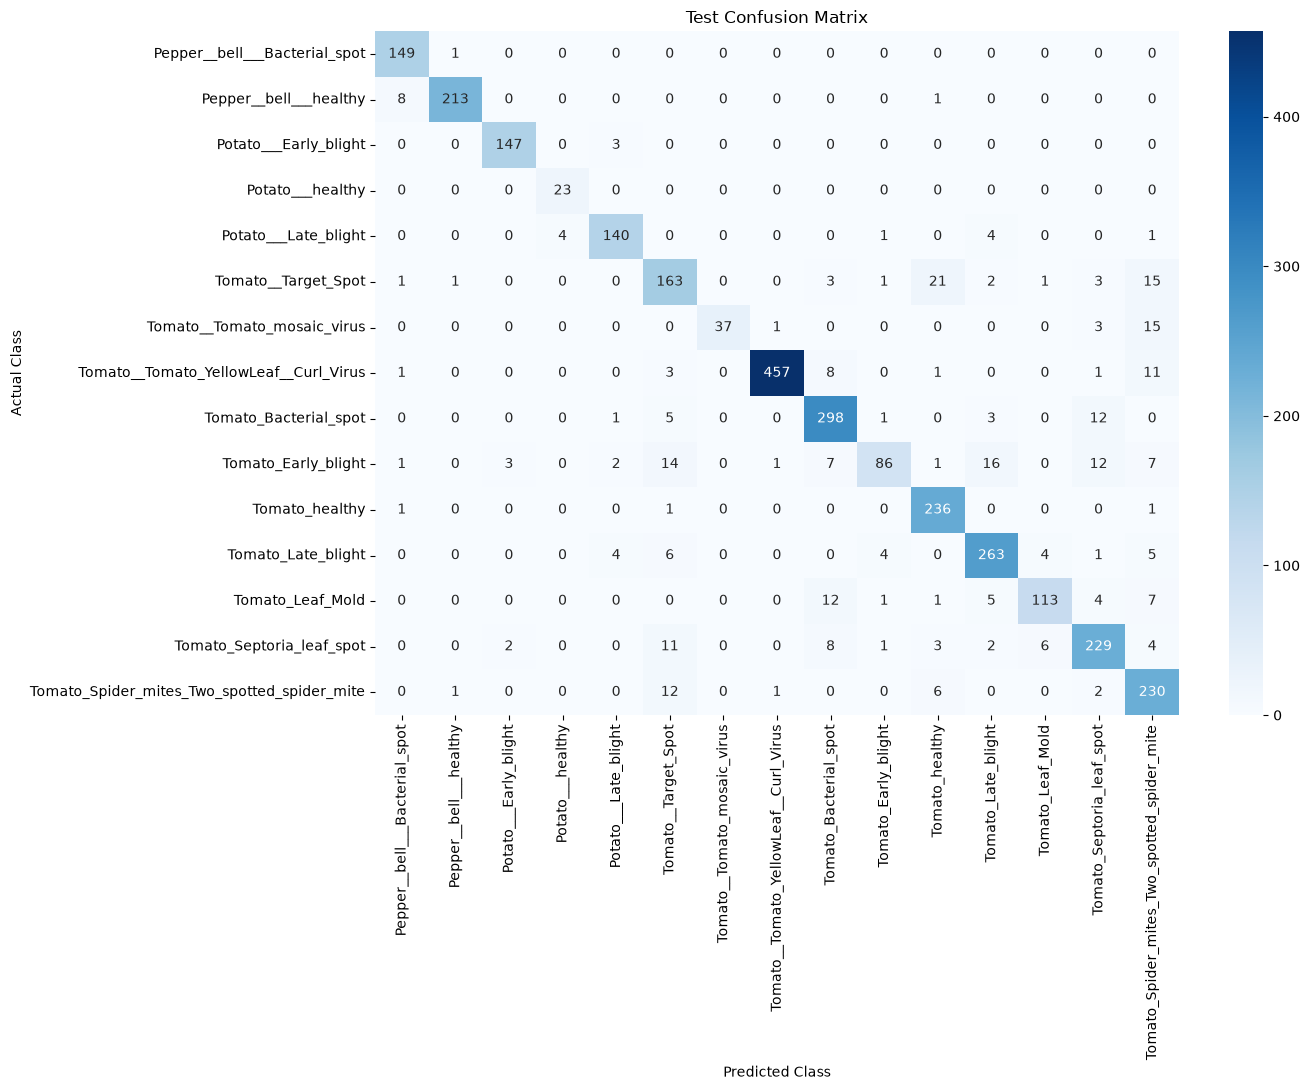

In [55]:
# Actual labels
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Predicted probabilities
y_prob = best_model.predict(test_ds)

# Predicted classes
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Visual Analysis of Predictions

Visualize five correctly classified and five incorrectly classified
test images to understand the model's prediction behavior.

Correct predictions demonstrate successful classification,
while incorrect predictions help identify challenging disease
patterns and potential areas for improvement.


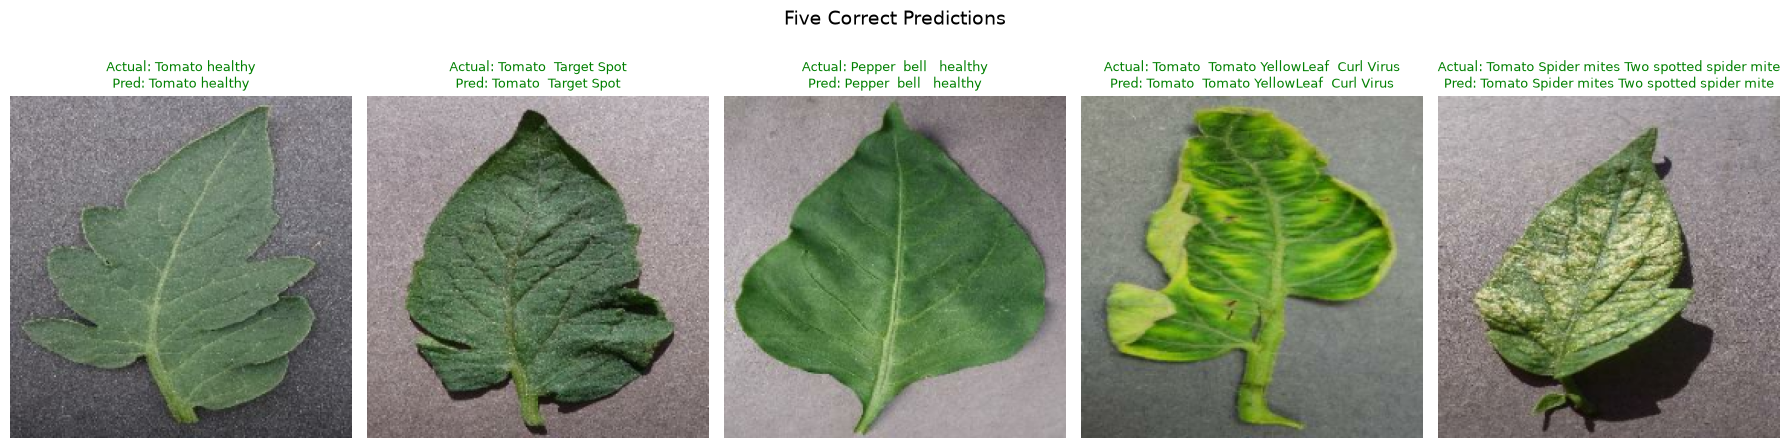

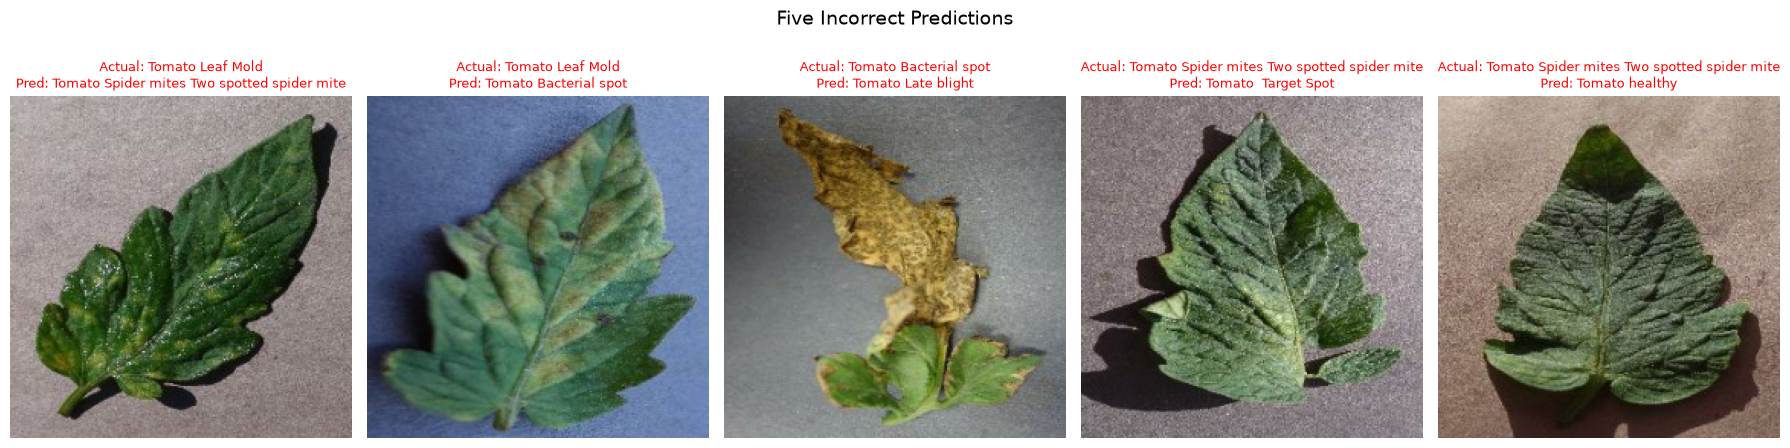

In [56]:
# Collect test images and labels
X_test = []
Y_test = []

for images, labels in test_ds:
    X_test.append(images.numpy())
    Y_test.append(labels.numpy())

X_test = np.concatenate(X_test)
Y_test = np.concatenate(Y_test)

correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

# Randomly select 5 examples from each
np.random.seed(42)

selected_correct = np.random.choice(
    correct_indices, 5, replace=False
)

selected_incorrect = np.random.choice(
    incorrect_indices, 5, replace=False
)

def show_predictions(indices, title, color):
    fig, axes = plt.subplots(1, 5, figsize=(18, 5))

    for ax, idx in zip(axes, indices):
        ax.imshow(X_test[idx].astype("uint8"))

        actual = CLASS_NAMES[y_true[idx]].replace("_", " ")
        predicted = CLASS_NAMES[y_pred[idx]].replace("_", " ")

        ax.set_title(
            f"Actual: {actual}\nPred: {predicted}",
            color=color,
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_predictions(
    selected_correct,
    "Five Correct Predictions",
    "green"
)

show_predictions(
    selected_incorrect,
    "Five Incorrect Predictions",
    "red"
)

In [ ]:
# Ek sample validation image
sample_image = val_images[0:1]

# Warm-up: initial TensorFlow overhead ko exclude karna
for _ in range(5):
    _ = model.predict(sample_image, verbose=0)

# Measure repeated inference
n_runs = 50
start_time = time.perf_counter()

for _ in range(n_runs):
    _ = model.predict(sample_image, verbose=0)

end_time = time.perf_counter()

avg_latency_ms = (
    (end_time - start_time) / n_runs
) * 1000

print(f"Average inference latency: {avg_latency_ms:.2f} ms/image")
print(f"Average throughput: {1000 / avg_latency_ms:.2f} images/second")

Average inference latency: 122.21 ms/image
Average throughput: 8.18 images/second



## Part 4: Bonus — Streamlit Application

Export the trained MobileNetV2 model and its corresponding class
labels to build an interactive crop disease prediction application.


In [ ]:
MODEL_PATH = Path("model_artifacts/best_mobilenetv2.keras")

with open("model_artifacts/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("Model exists:", MODEL_PATH.exists())
print("Number of saved classes:", len(CLASS_NAMES))
print("Class labels saved successfully.")


Model exists: True
Number of saved classes: 15
Class labels saved successfully.


In [60]:
best_model.save_weights(
    "model_artifacts/best_mobilenetv2.weights.h5"
)

print("Model weights exported successfully!")

Model weights exported successfully!
